# 03 · Modelagem
**Tech Challenge – Fase 2 · Grupo 01 · POSTECH Data Analytics**

Treinamos e comparamos **cinco abordagens**: uma de referência (que apenas aprova todos) e quatro algoritmos de classificação.
O foco é medir com honestidade quão bem cada um separa bons e maus pagadores.

In [1]:
RANDOM_STATE = 42   # semente fixa (split, modelos, CV)

import json, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
PROCESSED = "../data/processed/"

NUMERIC = ["CNT_CHILDREN", "CNT_FAM_MEMBERS", "AGE_YEARS", "YEARS_EMPLOYED", "LOG_INCOME", "LOG_INCOME_PER_MEMBER"]
BINARY = ["FLAG_OWN_CAR", "FLAG_OWN_REALTY", "FLAG_WORK_PHONE", "FLAG_PHONE", "FLAG_EMAIL", "IS_MALE", "IS_UNEMPLOYED_OR_RETIRED"]
CATEGORICAL = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "OCCUPATION_TYPE"]
FEATURES = NUMERIC + BINARY + CATEGORICAL

df = pd.read_csv(PROCESSED + "dataset_model.csv")
X, y, g = df[FEATURES], df["TARGET"].values, df["PROFILE_GROUP"].values
print("Base:", df.shape, "| variáveis preditoras:", len(FEATURES))

Base: (36457, 22) | variáveis preditoras: 18


## 1. Como dividimos os dados (sem vazamento)
- **80% treino / 20% teste**, estratificado (mesma proporção de maus nos dois lados).
- **Agrupado por perfil:** o notebook 01 mostrou que há só ~9,7 mil perfis únicos entre os 36 mil clientes. Colocamos **todos os clientes de um mesmo perfil no mesmo lado**,
  então o teste só contém perfis que o modelo nunca viu, como acontecerá com clientes novos na vida real.
- O **teste fica guardado** e só é usado para a nota final. A escolha do melhor modelo e o ajuste dos parâmetros usam **validação cruzada** dentro do treino (3 partes, também agrupadas).

In [2]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # 1 de 5 partes = 20% para teste
tr_idx, te_idx = next(splitter.split(X, y, g))
Xtr, Xte, ytr, yte, gtr, gte = X.iloc[tr_idx], X.iloc[te_idx], y[tr_idx], y[te_idx], g[tr_idx], g[te_idx]
assert not set(gtr) & set(gte)   # nenhum perfil nos dois conjuntos
print(f"Treino: {len(Xtr):,} clientes ({ytr.mean():.2%} maus) | Teste: {len(Xte):,} clientes ({yte.mean():.2%} maus)".replace(",", "."))
print("Perfis em comum entre treino e teste:", len(set(gtr) & set(gte)))
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

Treino: 29.166 clientes (11.77% maus) | Teste: 7.291 clientes (11.77% maus)
Perfis em comum entre treino e teste: 0


**Leitura:** treino e teste têm a mesma proporção de maus (11,77%) e **nenhum perfil aparece nos dois**. Esse cuidado é o que torna a nota do teste confiável.

## 2. Os modelos, em palavras simples
| Modelo | Como funciona | Pontos fortes / fracos |
|---|---|---|
| **Referência (Dummy)** | Dá a todos a mesma probabilidade (a taxa geral de maus) | Serve de régua: qualquer modelo útil precisa superá-lo |
| **Regressão Logística** | Soma o peso de cada característica para chegar a uma probabilidade | Simples e fácil de explicar; só captura relações "retas" |
| **Árvore de Decisão** | Faz uma sequência de perguntas sim/não (ex.: "tem imóvel?") | Muito interpretável; sozinha tende a decorar |
| **Random Forest** | Reúne centenas de árvores diferentes e tira a média | Mais estável que uma árvore; captura interações |
| **Gradient Boosting** | Constrói árvores em sequência, cada uma corrigindo os erros da anterior | Costuma ser o mais forte em dados tabulares |

Como há poucos maus pagadores, todos usam **pesos de classe** (`class_weight`), que fazem um erro em mau pagador "pesar" mais.
A escala e o one-hot ficam **dentro do Pipeline**, treinados só com os dados de treino de cada etapa.

In [3]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("bin", "passthrough", BINARY),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30), CATEGORICAL),
    ])

modelos = {
    "Baseline (Dummy)": (DummyClassifier(strategy="prior"), {}),
    "Regressão Logística": (LogisticRegression(max_iter=2000, class_weight="balanced"), {"clf__C": [0.01, 0.1, 1.0]}),
    "Árvore de Decisão": (DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                          {"clf__max_depth": [4, 6, 8], "clf__min_samples_leaf": [50, 200]}),
    "Random Forest": (RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
                      {"clf__max_depth": [6, 10], "clf__min_samples_leaf": [20, 60]}),
    "Gradient Boosting (HistGB)": (HistGradientBoostingClassifier(class_weight="balanced", early_stopping=True, random_state=RANDOM_STATE),
                                   {"clf__learning_rate": [0.03, 0.1], "clf__max_depth": [3, 5], "clf__min_samples_leaf": [50]}),
}

## 3. Treino, ajuste e escolha do ponto de corte
- Para cada modelo testamos algumas combinações de parâmetros (*grid search*) com validação cruzada e guardamos a de maior **ROC-AUC** (explicado abaixo).
- O modelo devolve uma **probabilidade de ser mau pagador**. Para virar decisão ("recusar" ou "aprovar") é preciso um **ponto de corte**. Usamos o ponto que mais separa os dois grupos
  (máxima diferença entre maus detectados e bons recusados, o ponto do KS), calculado **só com previsões de validação do treino**.
- O **modelo campeão é escolhido pela validação cruzada**, não pelo teste, para o teste continuar imparcial.

> **ROC-AUC em uma frase:** é a chance de o modelo dar uma probabilidade maior de "mau" a um mau pagador sorteado do que a um bom pagador sorteado.
> 0,50 = sorteio; 1,00 = perfeito.

In [4]:
def ponto_de_corte(y_true, p):
    fpr, tpr, thr = roc_curve(y_true, p)
    return float(thr[int(np.argmax(tpr - fpr))])      # máximo de (maus detectados - bons recusados)

resultados, probas, cortes, ajustados = [], {}, {}, {}
for nome, (clf, grade) in modelos.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    if grade:
        gs = GridSearchCV(pipe, grade, scoring="roc_auc", cv=cv, n_jobs=1, refit=True).fit(Xtr, ytr, groups=gtr)
        best, cv_auc, params = gs.best_estimator_, gs.best_score_, gs.best_params_
    else:   # baseline: AUC de CV calculado à mão
        aucs = [roc_auc_score(ytr[v], pipe.fit(Xtr.iloc[t], ytr[t]).predict_proba(Xtr.iloc[v])[:, 1]) for t, v in cv.split(Xtr, ytr, gtr)]
        best, cv_auc, params = pipe.fit(Xtr, ytr), float(np.mean(aucs)), {}
    oof = cross_val_predict(best, Xtr, ytr, cv=cv, groups=gtr, method="predict_proba")[:, 1]
    cortes[nome] = ponto_de_corte(ytr, oof) if grade else 1.01          # baseline: nunca recusa
    probas[nome] = best.predict_proba(Xte)[:, 1]; ajustados[nome] = best
    resultados.append({"modelo": nome, "ROC-AUC na validação cruzada (treino)": round(cv_auc, 3), "ROC-AUC no teste": round(roc_auc_score(yte, probas[nome]), 3),
                       "melhores parâmetros": str(params).replace("clf__", "")})
res = pd.DataFrame(resultados).set_index("modelo")
display(res)

,ROC-AUC na validação cruzada (treino),ROC-AUC no teste,melhores parâmetros
modelo,,,
Baseline (Dummy),0.500,0.500,{}
Regressão Logística,0.530,0.541,{'C': 0.01}
Árvore de Decisão,0.508,0.548,"{'max_depth': 4, 'min_samples_leaf': 50}"
Random Forest,0.532,0.530,"{'max_depth': 6, 'min_samples_leaf': 20}"
Gradient Boosting (HistGB),0.523,0.553,"{'learning_rate': 0.03, 'max_depth': 3, 'min_s..."


Modelo campeão (maior ROC-AUC na validação cruzada): Random Forest


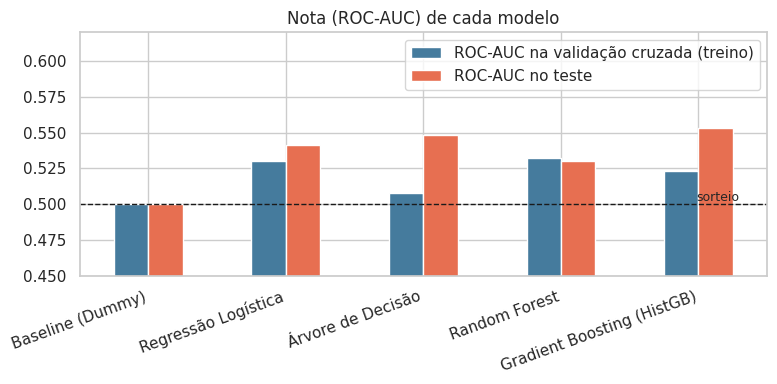

In [5]:
campeao = res.drop("Baseline (Dummy)")["ROC-AUC na validação cruzada (treino)"].idxmax()
print("Modelo campeão (maior ROC-AUC na validação cruzada):", campeao)

fig, ax = plt.subplots(figsize=(8, 4))
res[["ROC-AUC na validação cruzada (treino)", "ROC-AUC no teste"]].plot.bar(ax=ax, color=["#457b9d", "#e76f51"])
ax.axhline(0.5, color="k", ls="--", lw=1); ax.text(4.3, 0.502, "sorteio", ha="right", fontsize=9)
ax.set_ylim(0.45, 0.62); ax.set_title("Nota (ROC-AUC) de cada modelo"); ax.set_xlabel(""); plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.show()

**Leitura:**
- Todos os algoritmos ficam entre **0,51 e 0,55**, muito perto do sorteio (0,50). O **Random Forest** tem a melhor nota na validação cruzada e, por isso, é o campeão, mas
  a vantagem sobre os outros é pequena e **não é estatisticamente relevante** (veja o intervalo de confiança no notebook 04).
- As notas no treino (validação cruzada) e no teste são parecidas, o que indica que **não há "decoreba"**: o modelo generaliza o pouco que aprendeu.
- O resultado modesto não é falha de algoritmo: todos, de simples a sofisticados, chegam ao mesmo patamar. O limite está na **informação disponível** (só dados de cadastro).

## 4. Guardar os resultados para o notebook 04
Salvamos o modelo campeão e as previsões do teste em `data/processed/` (pasta não versionada: tudo é reproduzível rodando este notebook).

In [6]:
joblib.dump({"pipeline": ajustados[campeao], "threshold": cortes[campeao], "features": FEATURES, "modelo": campeao}, PROCESSED + "modelo_campeao.joblib")
pred = pd.DataFrame({"y": yte, "grupo": gte, **{k: v for k, v in probas.items()}})
pred.to_csv(PROCESSED + "predicoes_teste.csv", index=False)
res.to_csv(PROCESSED + "resultados_modelos.csv")
json.dump({"cortes": cortes, "campeao": campeao}, open(PROCESSED + "cortes.json", "w"))
np.save(PROCESSED + "idx_teste.npy", te_idx)
print("Artefatos salvos em data/processed/")

Artefatos salvos em data/processed/
